# Momentum crash risk: international replication and revision analysis

This notebook reproduces every empirical result used in the revised manuscript. It is intentionally written in a simple, cell-by-cell style. No classes or project-specific packages are required.

**How to run:** change only the `DATA_DIR` line in the next cell. Keep the four raw CSV filenames unchanged. The code cleans the Fama-French files automatically, creates the regression tables and figures, and saves all outputs in a `revision_outputs` folder inside `DATA_DIR`.


In [1]:
# 1. Packages and the only path you need to change
import os
import re
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

# CHANGE ONLY THIS LINE ON YOUR COMPUTER
DATA_DIR = r'C:\Users\HP16-af0022TU (D)\Desktop\Momentum crash_DEV_EM\data'

OUT_DIR = os.path.join(DATA_DIR, 'revision_outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
TAB_DIR = os.path.join(OUT_DIR, 'tables')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

print('Data folder:', DATA_DIR)
print('Output folder:', OUT_DIR)

Data folder: C:\Users\HP16-af0022TU (D)\Desktop\Momentum crash_DEV_EM\data
Output folder: C:\Users\HP16-af0022TU (D)\Desktop\Momentum crash_DEV_EM\data\revision_outputs


## 2. Read and clean the four raw factor files

The raw files contain explanatory text above the header. The developed five-factor file also contains annual summary rows after the monthly data. The cleaning rule keeps only six-digit `YYYYMM` dates and converts `-99.99` to missing values. This prevents annual rows or metadata from entering the monthly analysis.


In [2]:
def read_ff_csv(filename):
    path = os.path.join(DATA_DIR, filename)
    lines = open(path, 'r', encoding='utf-8-sig', errors='replace').read().splitlines()
    header_row = [i for i, line in enumerate(lines) if line.strip().startswith('Date,')][0]

    df = pd.read_csv(path, skiprows=header_row)
    date_text = df['Date'].astype(str).str.strip()
    monthly = date_text.str.fullmatch(r'\d{6}')
    df = df.loc[monthly].copy()
    date_text = date_text.loc[monthly]

    df['Date'] = pd.to_datetime(date_text, format='%Y%m') + pd.offsets.MonthEnd(0)
    for col in df.columns:
        if col != 'Date':
            df[col] = pd.to_numeric(df[col], errors='coerce').replace(-99.99, np.nan)

    return df.reset_index(drop=True)

DEV_5_FILE = 'Developed_5_Factors.csv'
DEV_MOM_FILE = 'Developed_MOM_Factor.csv'
EMG_5_FILE = 'Emerging_5_Factors.csv'
EMG_MOM_FILE = 'Emerging_MOM_Factor.csv'

dev5 = read_ff_csv(DEV_5_FILE)
devmom = read_ff_csv(DEV_MOM_FILE)
emg5 = read_ff_csv(EMG_5_FILE)
emgmom = read_ff_csv(EMG_MOM_FILE)

cleaning_check = pd.DataFrame({
    'File': [DEV_5_FILE, DEV_MOM_FILE, EMG_5_FILE, EMG_MOM_FILE],
    'Monthly rows kept': [len(dev5), len(devmom), len(emg5), len(emgmom)],
    'Start': [dev5.Date.min(), devmom.Date.min(), emg5.Date.min(), emgmom.Date.min()],
    'End': [dev5.Date.max(), devmom.Date.max(), emg5.Date.max(), emgmom.Date.max()]
})
display(cleaning_check)


,File,Monthly rows kept,Start,End
0,Developed_5_Factors.csv,430,1990-07-31,2026-04-30
1,Developed_MOM_Factor.csv,426,1990-11-30,2026-04-30
2,Emerging_5_Factors.csv,442,1989-07-31,2026-04-30
3,Emerging_MOM_Factor.csv,436,1990-01-31,2026-04-30


## 3. Merge five-factor and momentum files

Returns are converted from percentage points to decimals. The total market return used for the 24-month state variable is `Mkt-RF + RF`.


In [3]:
def merge_market(five_factor, momentum, market_name):
    df = pd.merge(five_factor, momentum, on='Date', how='inner')
    df = df.sort_values('Date').reset_index(drop=True)

    return_cols = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF', 'WML']
    for col in return_cols:
        df[col] = df[col] / 100.0

    df['MKT_total'] = df['Mkt-RF'] + df['RF']
    df['Market'] = market_name
    return df

dev = merge_market(dev5, devmom, 'Developed')
emg = merge_market(emg5, emgmom, 'Emerging')

sample_check = pd.DataFrame({
    'Market': ['Developed', 'Emerging'],
    'N': [len(dev), len(emg)],
    'Start': [dev.Date.min(), emg.Date.min()],
    'End': [dev.Date.max(), emg.Date.max()]
})
display(sample_check)


,Market,N,Start,End
0,Developed,426,1990-11-30,2026-04-30
1,Emerging,436,1990-01-31,2026-04-30


## 4. Construct market states, volatility, crash indicators, and subperiods

Baseline crashes use the unconditional 5% lower tail of WML, matching the definition in the original manuscript. This makes the binary dependent variable easy to interpret and directly addresses the referee's request to model crash probability.

A stricter robustness check also creates a **rolling 60-month crash threshold using only information available through month t-1**. The rolling definition is used to show how results change when even the crash threshold is fully ex ante.


In [4]:
def add_variables(df, vol_window=12, bear_window=24, crash_window=60):
    x = df.copy().sort_values('Date').reset_index(drop=True)

    x['MKT_cum_24_lag'] = (1 + x['MKT_total']).rolling(bear_window).apply(np.prod, raw=True).shift(1) - 1
    x['Bear_lag'] = (x['MKT_cum_24_lag'] < 0).astype(float)
    x.loc[x['MKT_cum_24_lag'].isna(), 'Bear_lag'] = np.nan

    x['Mkt_vol_12_lag'] = x['Mkt-RF'].rolling(vol_window).std().shift(1)
    x['WML_vol_12_lag'] = x['WML'].rolling(12).std().shift(1)
    x['WML_var_12_lag'] = x['WML_vol_12_lag'] ** 2

    x['Bear_x_MktVol'] = x['Bear_lag'] * x['Mkt_vol_12_lag']
    x['Up_Mkt'] = (x['Mkt-RF'] > 0).astype(float)
    x['Bear_x_Mkt'] = x['Bear_lag'] * x['Mkt-RF']
    x['Bear_x_Up_x_Mkt'] = x['Bear_lag'] * x['Up_Mkt'] * x['Mkt-RF']

    # Baseline crash indicators: unconditional lower-tail cutoffs
    q05 = x['WML'].quantile(0.05)
    q10 = x['WML'].quantile(0.10)
    x['Crash_5pct'] = (x['WML'] <= q05).astype(int)
    x['Crash_10pct'] = (x['WML'] <= q10).astype(int)

    # Strictly ex-ante robustness: rolling lower-tail cutoff based only on t-60,...,t-1
    x['Crash_q05_roll_lag'] = x['WML'].rolling(crash_window).quantile(0.05).shift(1)
    x['Crash_5pct_roll'] = np.where(
        x['Crash_q05_roll_lag'].notna(),
        (x['WML'] <= x['Crash_q05_roll_lag']).astype(int),
        np.nan
    )

    x['Subperiod'] = np.select(
        [x['Date'] <= pd.Timestamp('2007-12-31'), x['Date'] >= pd.Timestamp('2010-01-31')],
        ['Pre-2008', 'Post-2010'],
        default='Crisis/Transition'
    )
    return x

dev = add_variables(dev)
emg = add_variables(emg)

for name, df in [('Developed', dev), ('Emerging', emg)]:
    print(name, '5% crash cutoff =', round(df.WML.quantile(0.05) * 100, 2), '%')
    print(name, '5% crash observations =', int(df.Crash_5pct.sum()))


Developed 5% crash cutoff = -5.01 %
Developed 5% crash observations = 22
Emerging 5% crash cutoff = -3.67 %
Emerging 5% crash observations = 22


## 5. Helper functions for risk statistics and regression tables

Monthly OLS models use Newey-West/HAC standard errors with six lags, matching the original analysis. Binary crash models are estimated with a logit link and HAC covariance. Tables display coefficients with test statistics directly underneath and significance stars; p-values are not printed in the manuscript tables.


In [5]:
def max_drawdown(r):
    r = r.dropna()
    wealth = (1 + r).cumprod()
    peak = wealth.cummax()
    return (wealth / peak - 1).min()

def performance_stats(r):
    r = r.dropna()
    q05 = r.quantile(0.05)
    downside = r[r < 0].std(ddof=1)
    return {
        'N': len(r),
        'Mean_ann': r.mean() * 12,
        'Vol_ann': r.std(ddof=1) * np.sqrt(12),
        'Sharpe': (r.mean() * 12) / (r.std(ddof=1) * np.sqrt(12)),
        'Sortino': (r.mean() * 12) / (downside * np.sqrt(12)) if downside > 0 else np.nan,
        'Skewness': stats.skew(r, bias=False),
        'Excess_kurtosis': stats.kurtosis(r, fisher=True, bias=False),
        'VaR_5pct_monthly': q05,
        'CVaR_5pct_monthly': r[r <= q05].mean(),
        'Max_drawdown': max_drawdown(r)
    }

def hac_ols(df, yvar, xvars, lags=6):
    reg = df[[yvar] + xvars].dropna().copy()
    X = sm.add_constant(reg[xvars])
    model = sm.OLS(reg[yvar], X).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return model, reg

def hac_logit(df, yvar, xvars, lags=6):
    reg = df[[yvar] + xvars].dropna().copy()
    reg[yvar] = reg[yvar].astype(int)
    X = sm.add_constant(reg[xvars])
    model = sm.GLM(reg[yvar], X, family=sm.families.Binomial()).fit(
        cov_type='HAC', cov_kwds={'maxlags': lags}
    )
    return model, reg

def stars(p):
    if p < 0.01:
        return '***'
    if p < 0.05:
        return '**'
    if p < 0.10:
        return '*'
    return ''

def format_model(model, variables, decimals=4):
    rows = []
    for var in variables:
        if var in model.params.index:
            coef = f"{model.params[var]:.{decimals}f}{stars(model.pvalues[var])}"
            stat = f"({model.tvalues[var]:.2f})"
        else:
            coef, stat = '', ''
        rows.append((var, coef, stat))
    return rows


## 6. Table 1 - Momentum performance: full sample and subperiods

In [6]:
table1_full = []
for name, df in [('Developed', dev), ('Emerging', emg)]:
    row = {'Market': name}
    row.update(performance_stats(df['WML']))
    table1_full.append(row)
table1_full = pd.DataFrame(table1_full)

table1_sub = []
for name, df in [('Developed', dev), ('Emerging', emg)]:
    for sub in ['Pre-2008', 'Post-2010']:
        row = {'Market': name, 'Subperiod': sub}
        row.update(performance_stats(df.loc[df.Subperiod == sub, 'WML']))
        table1_sub.append(row)
table1_sub = pd.DataFrame(table1_sub)

table1_full.to_csv(os.path.join(TAB_DIR, 'Table1_PanelA_FullSample.csv'), index=False)
table1_sub.to_csv(os.path.join(TAB_DIR, 'Table1_PanelB_Subperiod.csv'), index=False)
display(table1_full.round(4))
display(table1_sub.round(4))


,Market,N,Mean_ann,Vol_ann,Sharpe,Sortino,Skewness,Excess_kurtosis,VaR_5pct_monthly,CVaR_5pct_monthly,Max_drawdown
0,Developed,426,0.0685,0.1285,0.5332,0.6014,-0.9322,6.9194,-0.0501,-0.0932,-0.4361
1,Emerging,436,0.1024,0.1045,0.9798,1.1058,-0.9911,4.5089,-0.0367,-0.0724,-0.3726


,Market,Subperiod,N,Mean_ann,Vol_ann,Sharpe,Sortino,Skewness,Excess_kurtosis,VaR_5pct_monthly,CVaR_5pct_monthly,Max_drawdown
0,Developed,Pre-2008,206,0.0987,0.1369,0.7211,0.8458,-0.3022,3.5380,-0.0636,-0.0957,-0.4305
1,Developed,Post-2010,196,0.0645,0.0957,0.6740,0.9800,-0.3674,2.0220,-0.0361,-0.0580,-0.2010
2,Emerging,Pre-2008,216,0.1094,0.1035,1.0562,1.2963,-0.6788,2.1879,-0.0376,-0.0678,-0.2161
3,Emerging,Post-2010,196,0.1248,0.0920,1.3563,1.8039,-0.2244,3.3825,-0.0317,-0.0541,-0.1452


## 7. Figures 1-2 - Cumulative wealth and drawdowns of static momentum

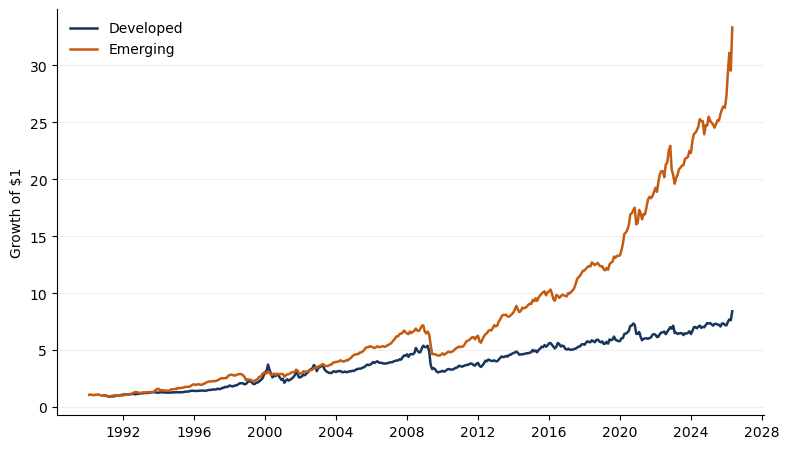

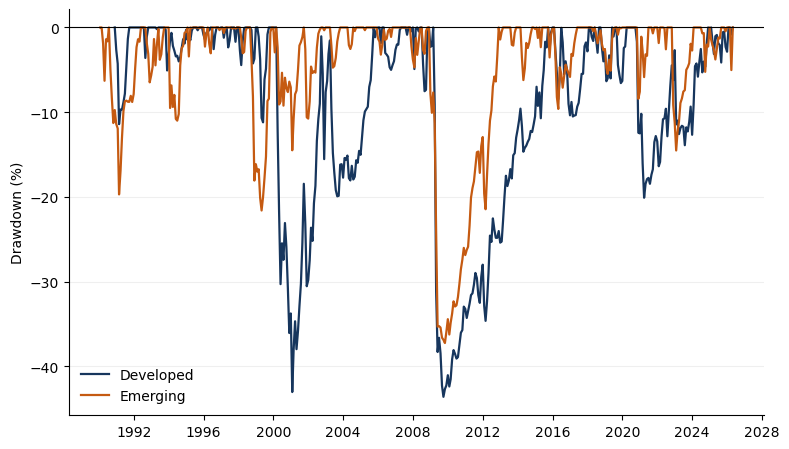

In [7]:
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

fig, ax = plt.subplots(figsize=(8.0, 4.6))
for name, df, color in [('Developed', dev, '#17365D'), ('Emerging', emg, '#C55A11')]:
    wealth = (1 + df.set_index('Date')['WML']).cumprod()
    ax.plot(wealth.index, wealth.values, linewidth=1.8, label=name, color=color)
ax.set_ylabel('Growth of $1')
ax.set_xlabel('')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.20)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'Figure1_Cumulative_Static_Momentum.png'), dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8.0, 4.6))
for name, df, color in [('Developed', dev, '#17365D'), ('Emerging', emg, '#C55A11')]:
    wealth = (1 + df.set_index('Date')['WML']).cumprod()
    dd = wealth / wealth.cummax() - 1
    ax.plot(dd.index, dd.values * 100, linewidth=1.6, label=name, color=color)
ax.axhline(0, linewidth=0.8, color='black')
ax.set_ylabel('Drawdown (%)')
ax.set_xlabel('')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.20)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'Figure2_Static_Momentum_Drawdowns.png'), dpi=300, bbox_inches='tight')
plt.show()


## 8. Table 2 - Worst monthly momentum returns and market states

In [8]:
worst_rows = []
for name, df in [('Developed', dev), ('Emerging', emg)]:
    w = df.nsmallest(8, 'WML')[['Date', 'WML', 'Mkt-RF', 'MKT_cum_24_lag', 'Bear_lag', 'Mkt_vol_12_lag']].copy()
    w.insert(1, 'Market', name)
    worst_rows.append(w)
table2 = pd.concat(worst_rows, ignore_index=True)
table2.to_csv(os.path.join(TAB_DIR, 'Table2_Worst_Months.csv'), index=False)
display(table2.round(4))


,Date,Market,WML,Mkt-RF,MKT_cum_24_lag,Bear_lag,Mkt_vol_12_lag
0,2009-04-30,Developed,-0.2426,0.1141,-0.4396,1.0,0.0800
1,2001-01-31,Developed,-0.1401,0.0187,0.1299,0.0,0.0437
2,2000-03-31,Developed,-0.1223,0.0466,0.3923,0.0,0.0365
3,2000-05-31,Developed,-0.1102,-0.0328,0.3152,0.0,0.0421
4,2020-11-30,Developed,-0.1092,0.1334,0.1686,0.0,0.0680
5,2000-04-30,Developed,-0.1076,-0.0577,0.4049,0.0,0.0372
6,2002-11-30,Developed,-0.1065,0.0514,-0.3448,1.0,0.0524
7,2009-05-31,Developed,-0.1040,0.0995,-0.4004,1.0,0.0885
8,2009-05-31,Emerging,-0.1484,0.1798,-0.2958,1.0,0.1254
9,2009-04-30,Emerging,-0.1439,0.1698,-0.3678,1.0,0.1130


## 9. Table 3 - Conditional WML returns and direct crash-probability models

Panel A retains the original conditional-return specification but labels it correctly as a WML-return regression. Panel B directly models the probability that WML falls into its market-specific 5% lower tail.


In [9]:
x_main = ['Bear_lag', 'Mkt_vol_12_lag', 'Bear_x_MktVol']
models_return = {}
models_crash5 = {}

for name, df in [('Developed', dev), ('Emerging', emg)]:
    models_return[name], _ = hac_ols(df, 'WML', x_main)
    models_crash5[name], _ = hac_logit(df, 'Crash_5pct', x_main)

rows = []
for var in ['const'] + x_main:
    out = {'Variable': var}
    for name in ['Developed', 'Emerging']:
        m = models_return[name]
        out[name] = f"{m.params[var]:.4f}{stars(m.pvalues[var])}\n({m.tvalues[var]:.2f})"
    rows.append(out)
rows.append({'Variable': 'Observations',
             'Developed': str(int(models_return['Developed'].nobs)),
             'Emerging': str(int(models_return['Emerging'].nobs))})
rows.append({'Variable': 'Adjusted R2',
             'Developed': f"{models_return['Developed'].rsquared_adj:.3f}",
             'Emerging': f"{models_return['Emerging'].rsquared_adj:.3f}"})
table3A = pd.DataFrame(rows)

rows = []
for var in ['const'] + x_main:
    out = {'Variable': var}
    for name in ['Developed', 'Emerging']:
        m = models_crash5[name]
        out[name] = f"{m.params[var]:.4f}{stars(m.pvalues[var])}\n({m.tvalues[var]:.2f})"
    rows.append(out)
rows.append({'Variable': 'Observations',
             'Developed': str(int(models_crash5['Developed'].nobs)),
             'Emerging': str(int(models_crash5['Emerging'].nobs))})
table3B = pd.DataFrame(rows)

table3A.to_csv(os.path.join(TAB_DIR, 'Table3_PanelA_Conditional_Return.csv'), index=False)
table3B.to_csv(os.path.join(TAB_DIR, 'Table3_PanelB_Crash_Logit.csv'), index=False)
display(table3A)
display(table3B)

for name in ['Developed', 'Emerging']:
    print(name, 'OLS N =', int(models_return[name].nobs), 'Adj. R2 =', round(models_return[name].rsquared_adj, 3))
    print(name, 'Logit N =', int(models_crash5[name].nobs))


,Variable,Developed,Emerging
0,const,0.0119***\n(2.78),0.0157***\n(3.49)
1,Bear_lag,0.0475*\n(1.84),0.0096\n(0.82)
2,Mkt_vol_12_lag,-0.1214\n(-0.94),-0.0781\n(-0.85)
3,Bear_x_MktVol,-0.9672**\n(-2.02),-0.2594\n(-1.26)
4,Observations,402,412
5,Adjusted R2,0.037,0.040


,Variable,Developed,Emerging
0,const,-6.5513***\n(-5.48),-4.1390***\n(-4.04)
1,Bear_lag,3.0740**\n(1.99),-0.1730\n(-0.12)
2,Mkt_vol_12_lag,72.0048***\n(4.05),10.4351\n(0.54)
3,Bear_x_MktVol,-41.0435*\n(-1.76),16.2607\n(0.72)
4,Observations,402,412


Developed OLS N = 402 Adj. R2 = 0.037
Developed Logit N = 402
Emerging OLS N = 412 Adj. R2 = 0.04
Emerging Logit N = 412


## 10. Figure 3 - Fitted 5% crash probabilities across volatility states

This figure is descriptive of the fitted logit model. It does not convert the in-sample association into a claim of guaranteed out-of-sample forecasting performance.


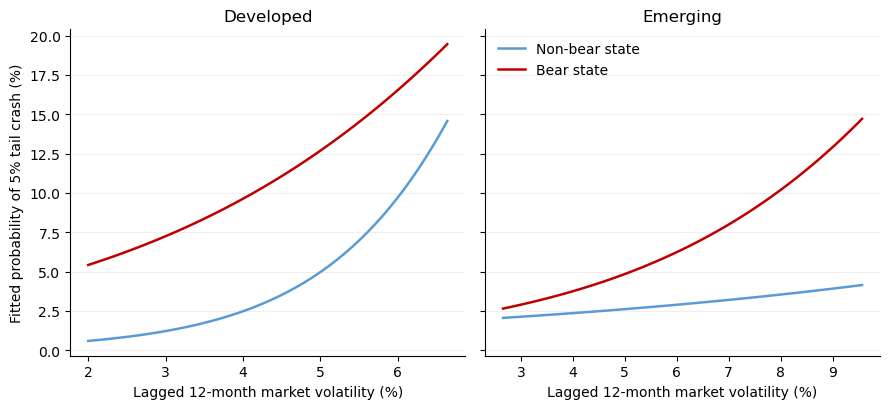

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.2), sharey=True)
for ax, name, df, color0, color1 in [
    (axes[0], 'Developed', dev, '#5B9BD5', '#C00000'),
    (axes[1], 'Emerging', emg, '#5B9BD5', '#C00000')
]:
    m = models_crash5[name]
    valid = df['Mkt_vol_12_lag'].dropna()
    grid = np.linspace(valid.quantile(0.05), valid.quantile(0.95), 100)
    for bear, label, color in [(0, 'Non-bear state', color0), (1, 'Bear state', color1)]:
        z = (m.params['const'] + m.params['Bear_lag'] * bear +
             m.params['Mkt_vol_12_lag'] * grid +
             m.params['Bear_x_MktVol'] * bear * grid)
        p = 1 / (1 + np.exp(-z))
        ax.plot(grid * 100, p * 100, linewidth=1.8, label=label, color=color)
    ax.set_xlabel('Lagged 12-month market volatility (%)')
    ax.set_title(name)
    ax.grid(axis='y', alpha=0.20)
axes[0].set_ylabel('Fitted probability of 5% tail crash (%)')
axes[1].legend(frameon=False, loc='upper left')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'Figure3_Fitted_Crash_Probability.png'), dpi=300, bbox_inches='tight')
plt.show()


## 11. Table 4 - Rebound dynamics and cross-market comparison

The pooled model is accompanied by a joint Wald test of the three emerging-market interaction terms. Failure to reject this joint null is interpreted only as insufficient evidence of different coefficients, not as proof that developed and emerging relationships are identical.


In [11]:
x_rebound = ['Mkt-RF', 'Bear_lag', 'Bear_x_Mkt', 'Bear_x_Up_x_Mkt']
models_rebound = {}
for name, df in [('Developed', dev), ('Emerging', emg)]:
    models_rebound[name], _ = hac_ols(df, 'WML', x_rebound)

combined = pd.concat([dev, emg], ignore_index=True)
combined['Emerging_dummy'] = (combined['Market'] == 'Emerging').astype(int)
combined['Emerging_x_Bear'] = combined['Emerging_dummy'] * combined['Bear_lag']
combined['Emerging_x_Vol'] = combined['Emerging_dummy'] * combined['Mkt_vol_12_lag']
combined['Emerging_x_Bear_x_Vol'] = combined['Emerging_dummy'] * combined['Bear_x_MktVol']

x_pool = ['Emerging_dummy', 'Bear_lag', 'Mkt_vol_12_lag', 'Bear_x_MktVol',
          'Emerging_x_Bear', 'Emerging_x_Vol', 'Emerging_x_Bear_x_Vol']
model_pool, _ = hac_ols(combined, 'WML', x_pool)

# Joint Wald test of the three emerging-specific slope interactions
param_names = list(model_pool.params.index)
R = np.zeros((3, len(param_names)))
for j, var in enumerate(['Emerging_x_Bear', 'Emerging_x_Vol', 'Emerging_x_Bear_x_Vol']):
    R[j, param_names.index(var)] = 1
wald = model_pool.wald_test(R, scalar=True)

rows = []
for var in ['const'] + x_rebound:
    out = {'Variable': var}
    for name in ['Developed', 'Emerging']:
        m = models_rebound[name]
        out[name] = f"{m.params[var]:.4f}{stars(m.pvalues[var])}\n({m.tvalues[var]:.2f})"
    rows.append(out)
rows.append({'Variable': 'Observations',
             'Developed': str(int(models_rebound['Developed'].nobs)),
             'Emerging': str(int(models_rebound['Emerging'].nobs))})
rows.append({'Variable': 'Adjusted R2',
             'Developed': f"{models_rebound['Developed'].rsquared_adj:.3f}",
             'Emerging': f"{models_rebound['Emerging'].rsquared_adj:.3f}"})
table4A = pd.DataFrame(rows)

rows = []
for var in ['const'] + x_pool:
    m = model_pool
    rows.append({'Variable': var, 'Pooled': f"{m.params[var]:.4f}{stars(m.pvalues[var])}\n({m.tvalues[var]:.2f})"})
rows.append({'Variable': 'Observations', 'Pooled': str(int(model_pool.nobs))})
rows.append({'Variable': 'Adjusted R2', 'Pooled': f"{model_pool.rsquared_adj:.3f}"})
table4B = pd.DataFrame(rows)

table4A.to_csv(os.path.join(TAB_DIR, 'Table4_PanelA_Rebound.csv'), index=False)
table4B.to_csv(os.path.join(TAB_DIR, 'Table4_PanelB_Pooled.csv'), index=False)
display(table4A)
display(table4B)
print('Joint Wald chi-square =', round(float(wald.statistic), 3), 'p-value =', round(float(wald.pvalue), 3))


,Variable,Developed,Emerging
0,const,0.0076***\n(4.31),0.0119***\n(8.11)
1,Mkt-RF,-0.0080\n(-0.11),0.0421\n(0.85)
2,Bear_lag,0.0074\n(0.91),0.0056\n(1.56)
3,Bear_x_Mkt,-0.3035*\n(-1.90),-0.0854\n(-0.94)
4,Bear_x_Up_x_Mkt,-0.5433\n(-1.30),-0.4605***\n(-2.82)
5,Observations,402,412
6,Adjusted R2,0.155,0.178


,Variable,Pooled
0,const,0.0119***\n(2.78)
1,Emerging_dummy,0.0038\n(0.61)
2,Bear_lag,0.0475*\n(1.84)
3,Mkt_vol_12_lag,-0.1214\n(-0.94)
4,Bear_x_MktVol,-0.9672**\n(-2.02)
5,Emerging_x_Bear,-0.0379\n(-1.34)
6,Emerging_x_Vol,0.0433\n(0.27)
7,Emerging_x_Bear_x_Vol,0.7078\n(1.36)
8,Observations,814
9,Adjusted R2,0.039


Joint Wald chi-square = 2.414 p-value = 0.491


## 12. Table 5 - Fama-French five-factor alpha regressions

In [12]:
ff_vars = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
models_ff5 = {}
for name, df in [('Developed', dev), ('Emerging', emg)]:
    models_ff5[name], _ = hac_ols(df, 'WML', ff_vars)

rows = []
for var in ['const'] + ff_vars:
    out = {'Variable': var}
    for name in ['Developed', 'Emerging']:
        m = models_ff5[name]
        out[name] = f"{m.params[var]:.4f}{stars(m.pvalues[var])}\n({m.tvalues[var]:.2f})"
    rows.append(out)
rows.append({'Variable': 'Observations',
             'Developed': str(int(models_ff5['Developed'].nobs)),
             'Emerging': str(int(models_ff5['Emerging'].nobs))})
rows.append({'Variable': 'Adjusted R2',
             'Developed': f"{models_ff5['Developed'].rsquared_adj:.3f}",
             'Emerging': f"{models_ff5['Emerging'].rsquared_adj:.3f}"})
table5 = pd.DataFrame(rows)
table5.to_csv(os.path.join(TAB_DIR, 'Table5_FF5_Alpha.csv'), index=False)
display(table5)
for name in ['Developed', 'Emerging']:
    print(name, 'N =', int(models_ff5[name].nobs), 'annualized alpha =', round(models_ff5[name].params['const'] * 12 * 100, 2), '%')


,Variable,Developed,Emerging
0,const,0.0070***\n(3.69),0.0082***\n(4.41)
1,Mkt-RF,-0.1644***\n(-3.02),-0.0286\n(-0.55)
2,SMB,0.2693\n(1.60),0.1953\n(1.57)
3,HML,-0.6649***\n(-2.94),-0.1041\n(-0.96)
4,RMW,0.2124\n(0.84),0.3751***\n(2.69)
5,CMA,0.4053\n(1.29),0.2028\n(1.34)
6,Observations,426,406
7,Adjusted R2,0.168,0.076


Developed N = 426 annualized alpha = 8.46 %
Emerging N = 406 annualized alpha = 9.89 %


## 13. Build the volatility-managed and dynamic strategies with no future-information normalization

### Volatility-managed rule
The raw exposure is inverse lagged WML variance. The normalization constant is an **expanding** mean of inverse variance, so every weight uses information observable by the portfolio-formation date. A leverage cap of 3 is applied.

### Dynamic state rule
The expected WML return is estimated from an expanding OLS using the bear indicator, lagged market volatility, and their interaction. At least 60 valid historical regression observations are required. Because the bear state itself requires 24 months of history, the first dynamic return appears after an 84-month burn-in (24 + 60). The dynamic raw exposure is predicted WML divided by lagged WML variance, normalized using an expanding mean absolute raw exposure, and capped to [-3, 3].


In [13]:
def build_strategies(df, cap=3.0, min_reg_obs=60):
    x = df.copy().sort_values('Date').reset_index(drop=True)
    x['ret_static'] = x['WML']

    # Volatility-managed strategy: strictly ex-ante expanding normalization
    raw_vol = (1 / x['WML_var_12_lag']).replace([np.inf, -np.inf], np.nan)
    c_vol_t = 1 / raw_vol.expanding(min_periods=1).mean()
    x['w_vol'] = (c_vol_t * raw_vol).clip(0, cap)
    x['ret_vol_managed'] = x['w_vol'] * x['WML']

    # Dynamic market-state strategy: expanding expected-return model
    x['pred_wml'] = np.nan
    xvars = ['Bear_lag', 'Mkt_vol_12_lag', 'Bear_x_MktVol']
    for i in range(len(x)):
        train = x.iloc[:i][['WML'] + xvars].dropna()
        current = x.loc[i, xvars]
        if len(train) >= min_reg_obs and current.notna().all():
            X = sm.add_constant(train[xvars])
            model = sm.OLS(train['WML'], X).fit()
            X_now = sm.add_constant(x.loc[[i], xvars], has_constant='add')
            x.loc[i, 'pred_wml'] = float(model.predict(X_now).iloc[0])

    raw_dynamic = (x['pred_wml'] / x['WML_var_12_lag']).replace([np.inf, -np.inf], np.nan)
    c_dynamic_t = 1 / raw_dynamic.abs().expanding(min_periods=1).mean()
    x['w_dynamic'] = (c_dynamic_t * raw_dynamic).clip(-cap, cap)
    x['ret_dynamic'] = x['w_dynamic'] * x['WML']
    return x

dev_strat = build_strategies(dev)
emg_strat = build_strategies(emg)

for name, df in [('Developed', dev_strat), ('Emerging', emg_strat)]:
    print('\n', name)
    for col in ['ret_static', 'ret_vol_managed', 'ret_dynamic']:
        valid = df[['Date', col]].dropna()
        print(col, 'N =', len(valid), 'first month =', valid.Date.min().date())



 Developed
ret_static N = 426 first month = 1990-11-30
ret_vol_managed N = 414 first month = 1991-11-30
ret_dynamic N = 342 first month = 1997-11-30

 Emerging
ret_static N = 436 first month = 1990-01-31
ret_vol_managed N = 424 first month = 1991-01-31
ret_dynamic N = 352 first month = 1997-01-31


## 14. Table 6 - Strategy performance, full sample and subperiods

In [14]:
strategy_labels = {
    'ret_static': 'Static',
    'ret_vol_managed': 'Vol-managed',
    'ret_dynamic': 'Dynamic'
}

def strategy_table(df, market, subperiod=None):
    use = df if subperiod is None else df[df.Subperiod == subperiod]
    rows = []
    for col, label in strategy_labels.items():
        row = {'Market': market, 'Strategy': label}
        if subperiod is not None:
            row['Subperiod'] = subperiod
        row.update(performance_stats(use[col]))
        rows.append(row)
    return rows

rows = []
rows += strategy_table(dev_strat, 'Developed')
rows += strategy_table(emg_strat, 'Emerging')
table6A = pd.DataFrame(rows)

rows = []
for market, df in [('Developed', dev_strat), ('Emerging', emg_strat)]:
    for sub in ['Pre-2008', 'Post-2010']:
        rows += strategy_table(df, market, sub)
table6B = pd.DataFrame(rows)

table6A.to_csv(os.path.join(TAB_DIR, 'Table6_PanelA_Strategy_FullSample.csv'), index=False)
table6B.to_csv(os.path.join(TAB_DIR, 'Table6_PanelB_Strategy_Subperiod.csv'), index=False)
display(table6A.round(4))
display(table6B.round(4))


,Market,Strategy,N,Mean_ann,Vol_ann,Sharpe,Sortino,Skewness,Excess_kurtosis,VaR_5pct_monthly,CVaR_5pct_monthly,Max_drawdown
0,Developed,Static,426,0.0685,0.1285,0.5332,0.6014,-0.9322,6.9194,-0.0501,-0.0932,-0.4361
1,Developed,Vol-managed,414,0.0652,0.0754,0.8648,1.2824,0.9341,7.4196,-0.0228,-0.0415,-0.1074
2,Developed,Dynamic,342,0.1003,0.1221,0.8213,1.3270,0.8782,4.6693,-0.0472,-0.0666,-0.2618
3,Emerging,Static,436,0.1024,0.1045,0.9798,1.1058,-0.9911,4.5089,-0.0367,-0.0724,-0.3726
4,Emerging,Vol-managed,424,0.1565,0.1214,1.2890,2.1358,1.0171,5.2384,-0.0388,-0.0597,-0.1545
5,Emerging,Dynamic,352,0.1131,0.0924,1.2235,1.6570,0.2746,3.4431,-0.0272,-0.0522,-0.1166


,Market,Strategy,Subperiod,N,Mean_ann,Vol_ann,Sharpe,Sortino,Skewness,Excess_kurtosis,VaR_5pct_monthly,CVaR_5pct_monthly,Max_drawdown
0,Developed,Static,Pre-2008,206,0.0987,0.1369,0.7211,0.8458,-0.3022,3.5380,-0.0636,-0.0957,-0.4305
1,Developed,Vol-managed,Pre-2008,194,0.0874,0.0779,1.1217,1.6636,1.4866,11.6741,-0.0142,-0.0355,-0.1074
2,Developed,Dynamic,Pre-2008,122,0.1429,0.1458,0.9798,1.5405,0.1558,0.7308,-0.0622,-0.0769,-0.2618
3,Developed,Static,Post-2010,196,0.0645,0.0957,0.6740,0.9800,-0.3674,2.0220,-0.0361,-0.0580,-0.2010
4,Developed,Vol-managed,Post-2010,196,0.0531,0.0742,0.7150,1.1144,0.3606,2.2776,-0.0283,-0.0434,-0.0882
5,Developed,Dynamic,Post-2010,196,0.0636,0.0907,0.7013,1.0778,0.3819,2.2137,-0.0351,-0.0531,-0.1191
6,Emerging,Static,Pre-2008,216,0.1094,0.1035,1.0562,1.2963,-0.6788,2.1879,-0.0376,-0.0678,-0.2161
7,Emerging,Vol-managed,Pre-2008,204,0.2005,0.1381,1.4516,2.7819,1.2253,4.9744,-0.0362,-0.0563,-0.1459
8,Emerging,Dynamic,Pre-2008,132,0.1287,0.1030,1.2493,1.6526,0.0211,2.9758,-0.0238,-0.0558,-0.1166
9,Emerging,Static,Post-2010,196,0.1248,0.0920,1.3563,1.8039,-0.2244,3.3825,-0.0317,-0.0541,-0.1452


## 15. Figures 4-5 - Strategy cumulative wealth

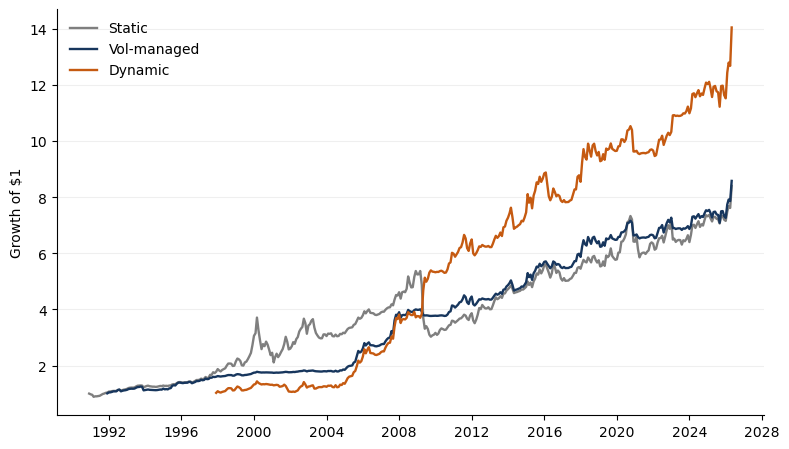

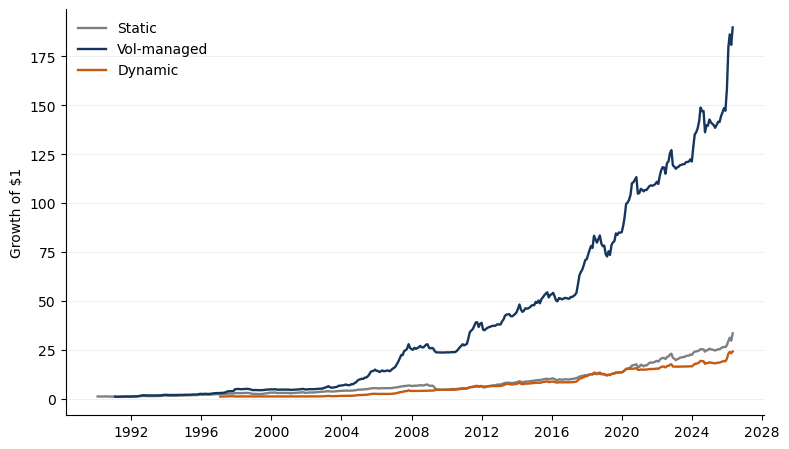

In [15]:
for fig_no, name, df in [(4, 'Developed', dev_strat), (5, 'Emerging', emg_strat)]:
    fig, ax = plt.subplots(figsize=(8.0, 4.6))
    colors = {'ret_static': '#7F7F7F', 'ret_vol_managed': '#17365D', 'ret_dynamic': '#C55A11'}
    for col, label in strategy_labels.items():
        r = df[['Date', col]].dropna().set_index('Date')[col]
        wealth = (1 + r).cumprod()
        ax.plot(wealth.index, wealth.values, linewidth=1.7, label=label, color=colors[col])
    ax.set_ylabel('Growth of $1')
    ax.set_xlabel('')
    ax.legend(frameon=False)
    ax.grid(axis='y', alpha=0.20)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f'Figure{fig_no}_{name}_Strategies.png'), dpi=300, bbox_inches='tight')
    plt.show()


## 16. Table 7 - Robustness and stability checks

Panel A re-estimates the conditional-return model before 2008 and after 2010. Panel B changes the market-volatility window. Panel C directly tests alternative crash definitions: a 10% unconditional tail and a rolling 60-month 5% threshold that uses no future information in the crash classification.


In [16]:
# Panel A: subperiod conditional-return regressions
rows = []
for market, df in [('Developed', dev), ('Emerging', emg)]:
    for sub in ['Pre-2008', 'Post-2010']:
        m, _ = hac_ols(df[df.Subperiod == sub], 'WML', x_main)
        rows.append({
            'Market': market,
            'Subperiod': sub,
            'Bear': f"{m.params['Bear_lag']:.4f}{stars(m.pvalues['Bear_lag'])}\n({m.tvalues['Bear_lag']:.2f})",
            'Vol': f"{m.params['Mkt_vol_12_lag']:.4f}{stars(m.pvalues['Mkt_vol_12_lag'])}\n({m.tvalues['Mkt_vol_12_lag']:.2f})",
            'Bear_x_Vol': f"{m.params['Bear_x_MktVol']:.4f}{stars(m.pvalues['Bear_x_MktVol'])}\n({m.tvalues['Bear_x_MktVol']:.2f})",
            'N': int(m.nobs),
            'Adj_R2': m.rsquared_adj
        })
table7A = pd.DataFrame(rows)

# Panel B: alternative volatility windows
rows = []
for vw in [6, 12, 24]:
    for market, base in [('Developed', merge_market(dev5, devmom, 'Developed')),
                         ('Emerging', merge_market(emg5, emgmom, 'Emerging'))]:
        temp = add_variables(base, vol_window=vw)
        m, _ = hac_ols(temp, 'WML', x_main)
        rows.append({
            'Market': market,
            'Vol_window': f'{vw} months',
            'Bear_x_Vol': f"{m.params['Bear_x_MktVol']:.4f}{stars(m.pvalues['Bear_x_MktVol'])}\n({m.tvalues['Bear_x_MktVol']:.2f})",
            'N': int(m.nobs)
        })
table7B = pd.DataFrame(rows)

# Panel C: direct crash-probability robustness
rows = []
for market, df in [('Developed', dev), ('Emerging', emg)]:
    for yvar, label in [('Crash_10pct', '10% unconditional tail'),
                        ('Crash_5pct_roll', '5% rolling 60-month tail')]:
        m, reg = hac_logit(df, yvar, x_main)
        rows.append({
            'Market': market,
            'Crash_definition': label,
            'Bear': f"{m.params['Bear_lag']:.4f}{stars(m.pvalues['Bear_lag'])}\n({m.tvalues['Bear_lag']:.2f})",
            'Vol': f"{m.params['Mkt_vol_12_lag']:.4f}{stars(m.pvalues['Mkt_vol_12_lag'])}\n({m.tvalues['Mkt_vol_12_lag']:.2f})",
            'Bear_x_Vol': f"{m.params['Bear_x_MktVol']:.4f}{stars(m.pvalues['Bear_x_MktVol'])}\n({m.tvalues['Bear_x_MktVol']:.2f})",
            'N': int(m.nobs),
            'Crashes': int(reg[yvar].sum())
        })
table7C = pd.DataFrame(rows)

table7A.to_csv(os.path.join(TAB_DIR, 'Table7_PanelA_Subperiod_Return.csv'), index=False)
table7B.to_csv(os.path.join(TAB_DIR, 'Table7_PanelB_Volatility_Windows.csv'), index=False)
table7C.to_csv(os.path.join(TAB_DIR, 'Table7_PanelC_Crash_Robustness.csv'), index=False)
display(table7A)
display(table7B)
display(table7C)


,Market,Subperiod,Bear,Vol,Bear_x_Vol,N,Adj_R2
0,Developed,Pre-2008,0.1593***\n(2.72),-0.0589\n(-0.24),-3.1155***\n(-2.74),182,0.003977
1,Developed,Post-2010,0.0030\n(0.08),-0.1258\n(-0.78),-0.2312\n(-0.30),196,0.005373
2,Emerging,Pre-2008,0.0141\n(0.73),-0.1852\n(-1.11),-0.1913\n(-0.57),192,0.009023
3,Emerging,Post-2010,-0.0261\n(-1.56),-0.0105\n(-0.08),0.3341\n(1.03),196,0.015513


,Market,Vol_window,Bear_x_Vol,N
0,Developed,6 months,-0.8660*\n(-1.65),402
1,Emerging,6 months,-0.3478*\n(-1.83),412
2,Developed,12 months,-0.9672**\n(-2.02),402
3,Emerging,12 months,-0.2594\n(-1.26),412
4,Developed,24 months,-0.3281\n(-0.53),402
5,Emerging,24 months,-0.2575\n(-1.00),412


,Market,Crash_definition,Bear,Vol,Bear_x_Vol,N,Crashes
0,Developed,10% unconditional tail,1.2556\n(1.12),38.6271***\n(3.14),-17.8313\n(-0.91),402,41
1,Developed,5% rolling 60-month tail,-3.7695**\n(-2.47),41.2515***\n(3.22),38.0917*\n(1.77),366,30
2,Emerging,10% unconditional tail,0.4665\n(0.43),21.9215*\n(1.80),-1.7056\n(-0.10),412,39
3,Emerging,5% rolling 60-month tail,-0.2526\n(-0.17),11.2068\n(0.54),13.4058\n(0.55),376,27


## 17. Crash frequencies by bear state and final reproducibility checks

In [17]:
frequency_rows = []
for market, df in [('Developed', dev), ('Emerging', emg)]:
    valid = df[df.Bear_lag.notna()].copy()
    for yvar, label in [('Crash_5pct', '5%'), ('Crash_10pct', '10%')]:
        frequency_rows.append({
            'Market': market,
            'Threshold': label,
            'Bear-state crash rate': valid.loc[valid.Bear_lag == 1, yvar].mean(),
            'Non-bear crash rate': valid.loc[valid.Bear_lag == 0, yvar].mean()
        })
crash_frequencies = pd.DataFrame(frequency_rows)
crash_frequencies.to_csv(os.path.join(TAB_DIR, 'Crash_Frequencies_By_State.csv'), index=False)
display(crash_frequencies.round(4))

# The dynamic strategy must lose exactly 84 observations relative to static.
assert len(dev_strat.ret_static.dropna()) - len(dev_strat.ret_dynamic.dropna()) == 84
assert len(emg_strat.ret_static.dropna()) - len(emg_strat.ret_dynamic.dropna()) == 84

# Static sample difference must equal the 10-month difference in momentum start dates.
assert len(emg) - len(dev) == 10

print('Reproducibility checks passed.')
print('All tables saved to:', TAB_DIR)
print('All figures saved to:', FIG_DIR)


,Market,Threshold,Bear-state crash rate,Non-bear crash rate
0,Developed,5%,0.1667,0.0298
1,Developed,10%,0.1970,0.0833
2,Emerging,5%,0.0863,0.0256
3,Emerging,10%,0.1439,0.0696


Reproducibility checks passed.
All tables saved to: C:\Users\HP16-af0022TU (D)\Desktop\Momentum crash_DEV_EM\data\revision_outputs\tables
All figures saved to: C:\Users\HP16-af0022TU (D)\Desktop\Momentum crash_DEV_EM\data\revision_outputs\figures
